In [1]:
# Cell 1: install
!pip install -q peft scikit-learn matplotlib

In [2]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os
FOLDER = "/content/drive/MyDrive"  # the Drive folder holding the CSV

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# Cell 2: config, data, prompt, label parser
import json, re, random
import numpy as np
import pandas as pd

CSV_PATH = f"{FOLDER}/synthetic_grants.csv"     # or a Drive path
MODEL_ID = "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B"
LABELS = ["Low", "Moderate", "High"]            # ordered worst -> best fit
PROFILE = ""        # optional: one sentence describing the target nonprofit; "" = let fine-tuning learn it
MAX_TRAIN = None    # e.g. 600 for a quick test run; None = all 2,400 training rows
random.seed(0); np.random.seed(0)

df = pd.read_csv(CSV_PATH)
assert set(df["label"]) == set(LABELS), df["label"].unique()
train_df = df[df["split"] == "train"]
val_df   = df[df["split"] == "val"]
test_df  = df[df["split"] == "test"]
if MAX_TRAIN:
    train_df = train_df.sample(MAX_TRAIN, random_state=0)

print(df["split"].value_counts().to_dict())
print("train label counts:", train_df["label"].value_counts().to_dict())

PROMPT = """You are screening grant announcements for relevance.
{profile}Read the grant announcement and rate how relevant it is: High, Moderate, or Low.
Answer with exactly one word: High, Moderate, or Low.

Grant announcement:
{text}"""

def user_message(text):
    profile = f"Target applicant profile: {PROFILE}\n" if PROFILE else ""
    return PROMPT.format(profile=profile, text=text)

def parse_label(raw):
    """Take what follows the last </think> (if present) and return the first label word found."""
    answer = raw.split("</think>")[-1]
    m = re.search(r"\b(High|Moderate|Low)\b", answer, re.IGNORECASE)
    return m.group(1).capitalize() if m else "Unparsed"

{'train': 2400, 'val': 300, 'test': 300}
train label counts: {'Moderate': 800, 'Low': 800, 'High': 800}


In [5]:
# Cell 3: load model + LoRA (fp32 base avoids T4 fp16-gradient errors; ~6 GB)
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model

tok = AutoTokenizer.from_pretrained(MODEL_ID)
base = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float32, device_map="auto")
# (if your transformers version rejects `dtype`, use torch_dtype=torch.float32)
base.gradient_checkpointing_enable()
base.enable_input_require_grads()

lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, task_type="CAUSAL_LM",
                  target_modules=["q_proj","k_proj","v_proj","o_proj","gate_proj","up_proj","down_proj"])
model = get_peft_model(base, lora)
model.print_trainable_parameters()

[transformers] `tokenizer_class` is `LlamaTokenizerFast` but `tokenizer.json` is ByteLevel; loading `TokenizersBackend`. Set `tokenizer_class` to `TokenizersBackend` in `tokenizer_config.json`.


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

trainable params: 18,464,768 || all params: 1,795,552,768 || trainable%: 1.0284


In [6]:
# Cell 4: tokenize (loss on the answer only) and train on the train split
from transformers import Trainer, TrainingArguments, DataCollatorForSeq2Seq

def make_prompt(text):
    return tok.apply_chat_template([{"role": "user", "content": user_message(text)}],
                                   add_generation_prompt=True, tokenize=False)

def build(text, label):
    prompt = make_prompt(text)
    open_think = "" if prompt.rstrip().endswith("<think>") else "<think>\n"   # template-version safe
    target = (open_think + "Judged on topic, location, and applicant eligibility.\n</think>\n\n"
              + label + tok.eos_token)
    p = tok(prompt, add_special_tokens=False)["input_ids"]
    t = tok(target, add_special_tokens=False)["input_ids"]
    return {"input_ids": p + t, "attention_mask": [1] * (len(p) + len(t)),
            "labels": [-100] * len(p) + t}

train_ds = [build(t, l) for t, l in zip(train_df["text"], train_df["label"])]
val_ds   = [build(t, l) for t, l in zip(val_df["text"],   val_df["label"])]

args = TrainingArguments(
    output_dir="r1_lora_relevance", num_train_epochs=2,
    per_device_train_batch_size=4, per_device_eval_batch_size=4, gradient_accumulation_steps=4,
    learning_rate=2e-4, logging_steps=10, eval_strategy="epoch",
    save_strategy="no", fp16=True, report_to="none",
)
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                  data_collator=DataCollatorForSeq2Seq(tok, padding=True, label_pad_token_id=-100))
trainer.train()

Epoch,Training Loss,Validation Loss
1,0.007419,0.007925
2,0.000231,0.000124


TrainOutput(global_step=300, training_loss=0.06951234665854523, metrics={'train_runtime': 797.1194, 'train_samples_per_second': 6.022, 'train_steps_per_second': 0.376, 'total_flos': 5904437015396352.0, 'train_loss': 0.06951234665854523, 'epoch': 2.0})

In [7]:
# Cell 5: batched generation + metrics (accuracy, precision, recall, F1, confusion matrix)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import matplotlib.pyplot as plt

def generate_raw(texts, batch_size=16, max_new_tokens=48):
    model.eval(); tok.padding_side = "left"
    outs = []
    for i in range(0, len(texts), batch_size):
        prompts = [make_prompt(t) for t in texts[i:i + batch_size]]
        enc = tok(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        with torch.no_grad():
            gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                                 pad_token_id=tok.pad_token_id)
        outs += tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return outs

def evaluate(rows, max_new_tokens=48, name="model"):
    raws = generate_raw(rows["text"].tolist(), max_new_tokens=max_new_tokens)
    y_true = rows["label"].tolist()
    y_pred = [parse_label(r) for r in raws]

    acc = accuracy_score(y_true, y_pred)
    p, r, f, support = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, zero_division=0)
    metrics = pd.DataFrame({"precision": p, "recall": r, "f1": f, "support": support}, index=LABELS)
    metrics.loc["macro avg"] = {"precision": p.mean(), "recall": r.mean(), "f1": f.mean(), "support": support.sum()}

    cols = LABELS + ["Unparsed"]                 # extra column catches outputs with no valid label
    cm = pd.DataFrame(confusion_matrix(y_true, y_pred, labels=cols)[:len(LABELS)],
                      index=[f"true {l}" for l in LABELS], columns=[f"pred {c}" for c in cols])

    print(f"=== {name} on {len(rows)} rows ===")
    print(f"Accuracy: {acc:.3f}   (always-guess-one-class baseline: {1/len(LABELS):.3f})")
    print(f"Unparsed outputs: {y_pred.count('Unparsed')}\n")
    print(metrics.round(3).to_string(), "\n")
    print("Confusion matrix (rows = true, columns = predicted):")
    print(cm.to_string())
    return {"raw": raws, "y_true": y_true, "y_pred": y_pred, "acc": acc, "metrics": metrics, "cm": cm}

def plot_cm(cm, path="confusion_matrix.png", title="Confusion matrix (test set)"):
    fig, ax = plt.subplots(figsize=(5.5, 4.2))
    ax.imshow(cm.values, cmap="Blues")
    ax.set_xticks(range(cm.shape[1]), [c.replace("pred ", "") for c in cm.columns])
    ax.set_yticks(range(cm.shape[0]), [i.replace("true ", "") for i in cm.index])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)
    top = cm.values.max()
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            v = cm.values[i, j]
            ax.text(j, i, v, ha="center", va="center", color="white" if v > top / 2 else "black")
    fig.tight_layout(); fig.savefig(path, dpi=200); plt.show()

=== Fine-tuned DeepSeek-R1-Distill-Qwen-1.5B on 300 rows ===
Accuracy: 0.627   (always-guess-one-class baseline: 0.333)
Unparsed outputs: 0

           precision  recall     f1  support
Low            0.886   0.780  0.830      100
Moderate       0.471   0.900  0.619      100
High           0.952   0.200  0.331      100
macro avg      0.770   0.627  0.593      300 

Confusion matrix (rows = true, columns = predicted):
               pred Low  pred Moderate  pred High  pred Unparsed
true Low             78             21          1              0
true Moderate        10             90          0              0
true High             0             80         20              0


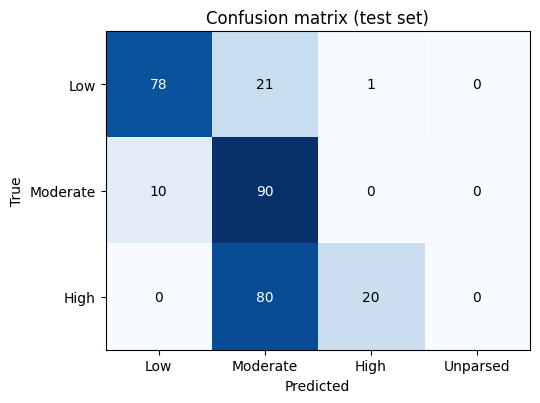

### Example 1 (correct prediction)

**Input (grant announcement):**
> Funding priorities: local economic development in rural regions. Applications are accepted from organizations active in the regions of Georgia (the country). Any legally registered organization may apply. Grant size: €10,000. Closing date: 4 May 2026. Applications are reviewed on a rolling basis.

**True label:** Moderate

**Model output (raw):**
```
Judged on topic, location, and applicant eligibility.
</think>

Moderate
```

**Parsed prediction:** Moderate

### Example 2 (incorrect prediction)

**Input (grant announcement):**
> Funding priorities: fintech and blockchain platforms. Applications are accepted from organizations active in the regions of Georgia (the country). Small businesses with paying customers are eligible. Grant size: $50,000. Closing date: 27 November 2026. Shortlisted applicants will be invited to an interview.

**True label:** Low

**Model output (raw):**
```
Judged on topic, location, and appl

In [8]:
# Cell 6: final test-set evaluation (run once) + two report examples
def report_examples(rows, res, path="report_examples.md"):
    rows = rows.reset_index(drop=True)
    ok  = [i for i, (t, p) in enumerate(zip(res["y_true"], res["y_pred"])) if t == p]
    bad = [i for i, (t, p) in enumerate(zip(res["y_true"], res["y_pred"])) if t != p]
    picks = [(ok[0], "correct")]
    if bad:
        picks.append((bad[0], "incorrect"))
    else:   # no mistakes: show a correct example from a different class
        picks.append((next(i for i in ok if res["y_true"][i] != res["y_true"][ok[0]]), "correct"))
    out = []
    for n, (i, kind) in enumerate(picks, 1):
        out.append(f"### Example {n} ({kind} prediction)\n\n"
                   f"**Input (grant announcement):**\n> {rows.loc[i, 'text']}\n\n"
                   f"**True label:** {res['y_true'][i]}\n\n"
                   f"**Model output (raw):**\n```\n{res['raw'][i].strip()}\n```\n\n"
                   f"**Parsed prediction:** {res['y_pred'][i]}\n")
    text = "\n".join(out); print(text); open(path, "w").write(text)

test_res = evaluate(test_df, name="Fine-tuned DeepSeek-R1-Distill-Qwen-1.5B")
plot_cm(test_res["cm"])
test_res["metrics"].round(3).to_csv("test_metrics.csv")
test_res["cm"].to_csv("test_confusion_matrix.csv")
report_examples(test_df, test_res)

In [ ]:
# zero-shot baseline (LoRA switched off), 60 rows because the reasoning model is slow
with model.disable_adapter():
    zs = evaluate(test_df.head(60), max_new_tokens=1024, name="Zero-shot, no fine-tuning (first 60 test rows)")